# Overload and prediction. Baseline, H1 and its confirmatory test

This notebook runs the package `overload` in the repository [`overload-prediction`](https://github.com/ucchol/overload-prediction). Every model, measure and decision rule comes from `ANALYSIS_PLAN.md`, frozen before the tests ran, and every result is logged in `STORY.md`. Every result shown here was verified twice before it was reported, by a second run and by an independent reimplementation (`verification/`).

**Colab.** Run the cells in order. The first cell clones the repository if it is not already in `/content`. Saved results are loaded, so every section displays without the development data. To rerun the development analyses, upload the study's data file `Updated_Choice_Overload.csv` to `/content` and set `RECOMPUTE = True` (about 1 minute for the baseline, 3 for H1 and 13 for the confirmatory test with two processes). The open snack choice data of the confirmatory test are fetched from GitHub at a pinned commit.

In [1]:
import os, sys, json, subprocess, zipfile
from pathlib import Path

REPO = Path(os.environ.get("OVERLOAD_REPO", "/content/overload-prediction"))
DATA = Path(os.environ.get("OVERLOAD_DATA", "/content/Updated_Choice_Overload.csv"))
RECOMPUTE = False
JOBS = 2

if not REPO.exists():
    if Path("/content/overload-prediction.zip").exists():
        zipfile.ZipFile("/content/overload-prediction.zip").extractall("/content")
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/ucchol/overload-prediction.git", str(REPO)],
                       check=True)
sys.path.insert(0, str(REPO / "src"))
os.chdir(REPO)
HAVE_DATA = DATA.exists()

import overload
from overload.engine import plan_digest
print("package", overload.__version__, "| plan digest", plan_digest()[:16])
print("development data", "found" if HAVE_DATA else "not found, saved results are shown")

package 0.1.0 | plan digest d3bfe629fe812074
development data found


## 1. The rebuilt pipeline reproduces the earlier one

**Why.** Every later result rests on the new code, so it must first reproduce the earlier (AAMAS) pipeline from the raw data.

**How.** The test suite checks every measure and model on synthetic cases, then compares the rebuilt pipeline with the earlier one: rubric shares, attainable scores, per trial held out and fitted log scores and overlaps of QR, CL, DbS and MLBA, for the original sample and four bootstrap replicates.

In [2]:
env = dict(os.environ, OVERLOAD_DATA=str(DATA), PYTHONPATH=str(REPO / "src"))
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], cwd=REPO, env=env, capture_output=True, text=True)
print(r.stdout[-600:] or r.stderr[-600:])

.....................................................................    [100%]



**Findings.**

1. Every test passed. Rubric shares match the earlier ones exactly, and per trial log scores and overlaps match within 1e-6 bits (largest difference 2.5e-8, the earlier optimizer's tolerance), for the original sample and for bootstrap replicates 0, 1, 499 and 999.
2. The published completeness values and their intervals are reproduced once each trial's attainable log score is held at its full sample value inside the bootstrap (plan, Amendment 1).

## 2. R0, the baseline

**Why.** The descriptive starting point. How far each one parameter model predicts unseen trials, with the comparison models averaged over rivals as well as summed.

**How.** Held out (each trial predicted from the other five) and fitted completeness, and held out overlap, per task and information level, with differences from CL and 1000 participant resamples.

In [3]:
from overload.experiments import baseline
out = REPO / "results" / "baseline"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    baseline.run(DATA, out, replicates=1000, jobs=JOBS)
print((out / "table_baseline.md").read_text())

| Task | Model | Held out completeness, % | Low | High | Fitted, % | Held out overlap, % | Completeness minus CL, points | Overlap minus CL, points |
|---|---|---|---|---|---|---|---|---|
| file | QR | 21.9 [14.3, 30.1] * | 12.4 [4.1, 21.6] * | 30.6 [20.5, 41.5] * | 23.9 | 55.0 | -7.7 [-11.7, -3.9] * | -3.2 [-4.2, -1.9] * |
| file | CL | 29.5 [20.2, 39.2] * | 29.1 [18.1, 42.5] * | 29.9 [19.1, 41.4] * | 32.9 | 58.2 |  |  |
| file | DbS_avg | 32.1 [22.4, 42.2] * | 30.2 [19.3, 42.7] * | 33.8 [21.7, 46.3] * | 33.5 | 58.7 | 2.6 [0.7, 4.4] * | 0.5 [0.0, 1.4] |
| file | MLBA_avg | 31.4 [22.2, 41.3] * | 30.2 [19.7, 42.1] * | 32.5 [20.6, 44.7] * | 32.2 | 58.4 | 1.8 [-0.9, 4.6] | 0.1 [-0.9, 1.4] |
| file | DbS_sum | 23.9 [16.1, 32.0] * | 19.3 [8.3, 31.0] * | 28.2 [17.6, 39.2] * | 25.5 | 54.7 | -5.6 [-10.2, -1.5] * | -3.5 [-4.2, -1.0] * |
| file | MLBA_sum | 22.6 [15.0, 30.2] * | 20.7 [11.4, 31.5] * | 24.3 [13.5, 35.7] * | 24.3 | 54.1 | -6.9 [-12.4, -2.2] * | -4.1 [-4.9, -1.4] * |
| laptop | QR |

**Findings.**

1. Held out completeness of CL was 29.5% [20.2, 39.2] for files, as published, and 55.4% [43.1, 67.9] for laptops. The laptop value is higher than the published 50.3% because the earlier analysis used wrong definitions of laptop trials 5 and 6 (Section 5, plan Amendment 4).
2. Averaged comparison scores predicted unseen trials at least as well as CL in both tasks. DbS_avg exceeded CL by 2.6 points [0.7, 4.4] for files and 3.9 [1.6, 6.5] for laptops, and MLBA_avg by 1.8 [-0.9, 4.6] and 4.3 [0.3, 8.7], the last not clear since its basic interval touches zero. For laptops overlap rose with both, by 2.3 and 3.8 points.
3. Summing the comparisons over every rival instead cost 5.6 and 6.9 points against CL for files, so how sensitivity scales with set size matters. That is test A1a of H1.


## 3. H1, narrowing with set size

**Why.** The story's first claim. As options grow, do choices narrow (concentrate on fewer options than a model expects) or become noisier?

**How.** Three pre-specified tests (plan Section 7 with Amendment 2).
- B1, behavior. Effective options as a share of the set, observed against held out CL predictions sampled at the observed number of choices. Predicted, a negative mean gap and a negative slope per doubling of the options.
- A1a, algorithm. Sensitivity scaled by ((n - 1) / 7) to the power beta, with beta from -1 (noisier with more options) to +1 (sharper), for CL, DbS_avg and MLBA_avg. Predicted, beta +0.5 beats beta 0 and beta -0.5 loses to it.
- A1b, algorithm. Elimination by aspects with rubric weights against CL, 32 option trials minus 8 option trials.

# H1, narrowing with set size (development data)

## file

### A1a, set size scaling, held out completeness (%)

| Model | beta | Completeness | 8 | 16 | 32 | Overlap % | Minus beta 0 | Overlap minus beta 0 |
|---|---|---|---|---|---|---|---|---|
| CL | -1.0 | 28.4 [20.0, 37.0] * | 61.9 | 3.0 | 21.1 | 57.6 | -1.1 [-5.5, 2.8] | -0.6 [-2.3, 1.6] |
| CL | -0.5 | 29.9 [21.1, 39.1] * | 61.7 | -5.8 | 32.5 | 58.8 | 0.4 [-2.0, 2.5] | 0.5 [-1.0, 1.6] |
| CL | +0.0 | 29.5 [20.2, 39.2] * | 54.0 | -7.7 | 39.3 | 58.2 |  |  |
| CL | +0.5 | 26.6 [17.8, 35.5] * | 38.0 | 0.3 | 38.4 | 56.4 | -3.0 [-5.4, -0.8] * | -1.8 [-2.4, -0.4] * |
| CL | +1.0 | 22.2 [14.3, 30.4] * | 21.9 | 6.8 | 35.1 | 54.6 | -7.3 [-12.1, -3.2] * | -3.6 [-4.5, -1.5] * |
| DbS_avg | -1.0 | 27.8 [19.3, 37.0] * | 53.3 | 12.9 | 18.5 | 56.8 | -4.3 [-9.3, 0.3] | -2.0 [-3.9, -0.2] * |
| DbS_avg | -0.5 | 31.3 [22.1, 41.0] * | 55.9 | 8.3 | 29.4 | 58.6 | -0.8 [-3.5, 1.5] | -0.1 [-1.7, 0.7] |
| DbS_avg | +0.0 | 32.1 [22.4, 42.2] * | 52.4 | 5.8

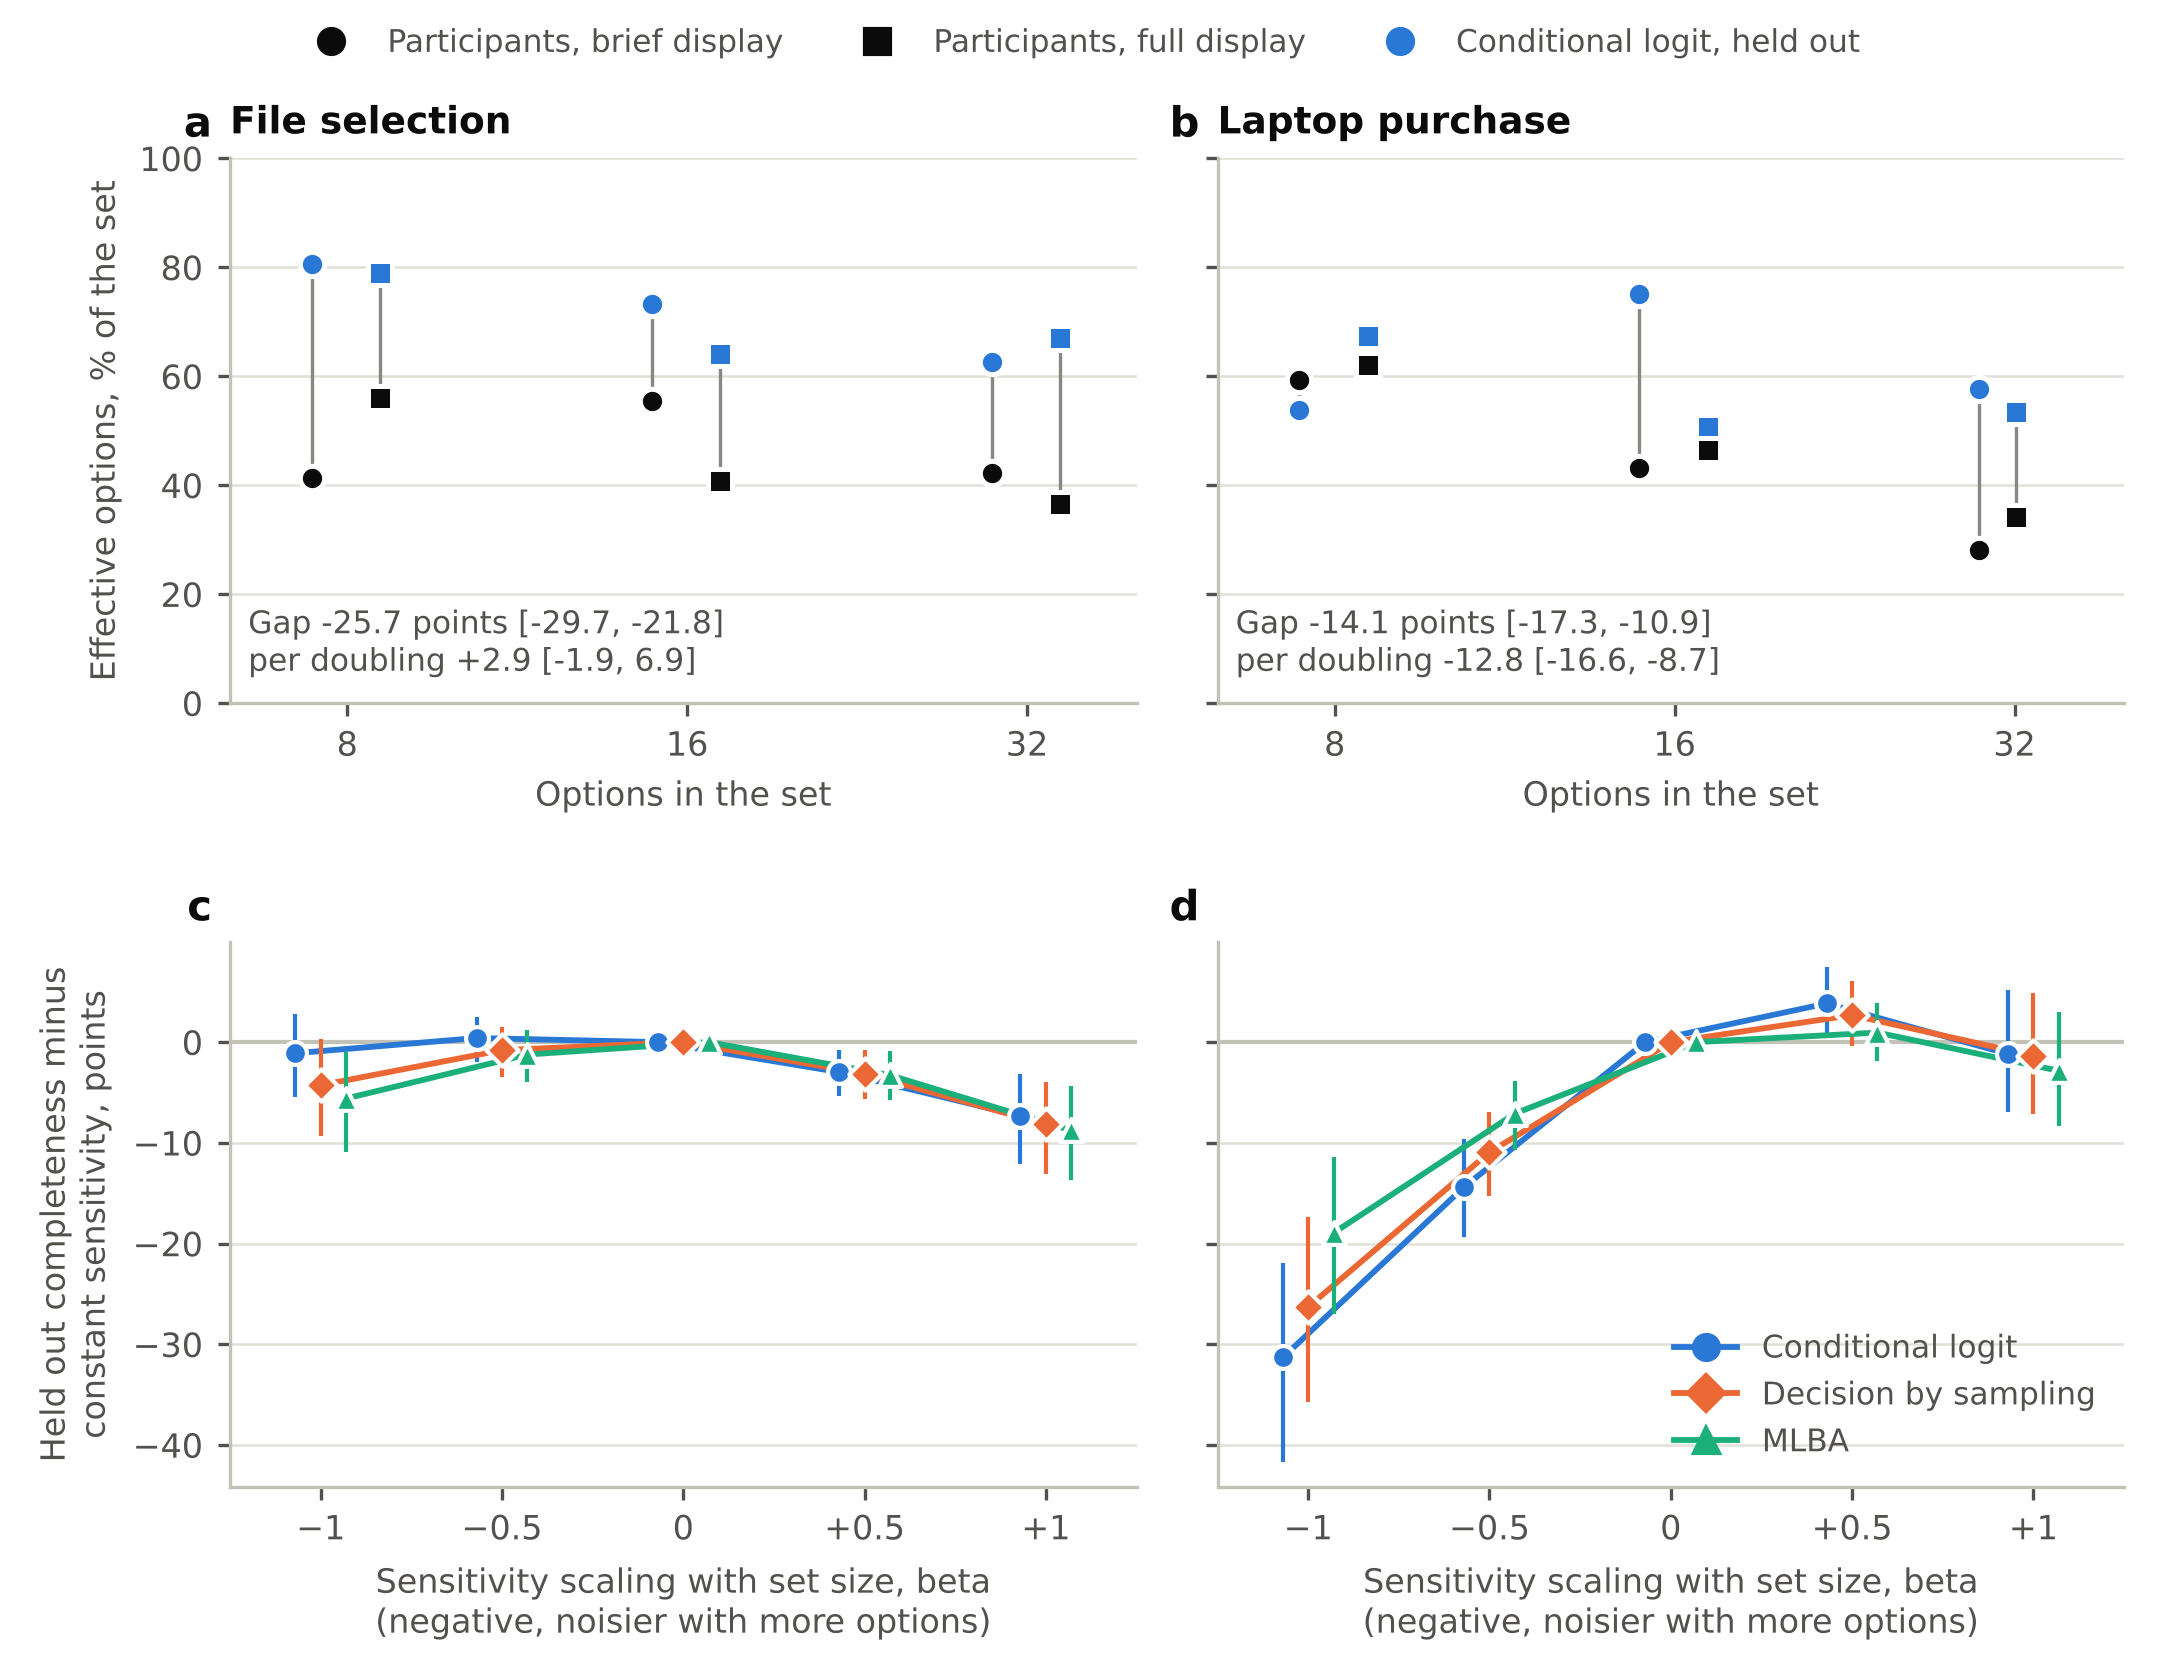

In [4]:
from overload.experiments import h1_narrowing
from overload.figures import figure_h1
from IPython.display import Image, display
out = REPO / "results" / "h1"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    h1_narrowing.run(DATA, out, replicates=1000, jobs=JOBS)
summary = json.loads((out / "summary.json").read_text())
figure_h1(summary, out / "fig_h1_narrowing")
print((out / "table_h1.md").read_text())
display(Image(filename=str(out / "fig_h1_narrowing.png"), width=900))

**Findings.**

1. People narrowed. Their choices were more concentrated than held out CL predictions in 11 of the 12 trials, by 25.7 points of the set for files [-29.7, -21.8] and 14.1 for laptops [-17.3, -10.9]. For laptops the gap widened by 12.8 points with each doubling of the options [-16.6, -8.7], for files it did not (+2.9 [-1.9, 6.9]). B1 supports H1 for laptops only.
2. The noise account failed. Lowering sensitivity as sets grow (beta -0.5) cut laptop completeness by 14.4 points [-19.4, -9.6] and left files unchanged (+0.4 [-2.0, 2.5]), with the same pattern in all three model families.
3. Sharpening split the tasks. Raising sensitivity with set size (beta +0.5) raised laptop completeness by 3.8 points [0.4, 7.5] and lowered file completeness by 3.0 [-5.4, -0.8]. A1a supports H1 for laptops and not for files.
4. Screening on the rubric's attributes in the rubric's order predicted badly, 32 and 41 points below CL for files and laptops. Its deficit shrank from 8 to 32 file options, which passes the A1b rule for files, but it never overtook CL.

**Story.** For laptops, choices grew both more concentrated and sharper as sets grew, the pattern the snack data confirm in Section 6. For files the concentration is there but uniform sharpening does not reproduce it, so people concentrated on file options for reasons the coded attributes and the rubric do not carry.


## 4. Verification of R0 and H1

**Why.** Every reported number must be right. Each result is therefore computed twice by the package and once more by a separate implementation written only from the plan, the raw data and a written brief, without access to the package.

**How.** A second run of every experiment from a fresh process, compared value by value with the saved results, and the comparison below of the package with the independent implementation (archived in `verification/independent`). `sh verification/run_independent.sh PATH_TO_CSV` reruns the independent implementation from scratch.

In [5]:
if HAVE_DATA:
    cmd = [sys.executable, "verification/compare_independent.py", "--data", str(DATA),
           "--independent", "verification/independent/results_storyboard.json", "--baseline", "results/baseline", "--h1", "results/h1"]
    r = subprocess.run(cmd, cwd=REPO, env=env, capture_output=True, text=True)
    print(r.stdout[-2500:] or r.stderr[-2500:])
else:
    print("The comparison reads the development data, so it runs only when the data file is present.")

Independent reimplementation against the package

Kind            checked   largest difference
benchmark            12   4.44e-16
choice share        222   0
clear                56   0
completeness        172   9.95e-13
concentration        40   2.78e-17
decision             14   0
difference           76   7.32e-13
interval            408   1.88e-12
overlap              42   2e-15
p value              60   0
parameter            16   5.33e-15
replicate            48   6.82e-13
rubric share         12   0
trial bits          156   1.98e-14
trial overlap        72   5.11e-15

Every value agrees within tolerance.



**Findings.**

1. The second run reproduced every saved value exactly, including all 1000 bootstrap replicates of both experiments.
2. The independent implementation agreed with the package on every compared value, from choice shares and rubric shares to intervals, p values and every hypothesis decision, with a largest difference of 2e-12. This held at the first verification on 9 October and again on 14 October, after both implementations were rerun on the corrected laptop definitions.
3. The independent implementation raised issues with the inputs. The designers' laptop scores contradicted the coded attributes in the two 32 option laptop trials, which led to the correction in Section 5. The file A1b result depends on how the median is defined for an even number of options, so it is reported as fragile.

**Story.** The computations stand, for files and, after the correction, for laptops.


## 5. Correcting the laptop displays (plan Amendment 4)

**Why.** The verifier found that in the two 32 option laptop trials, laptops with identical coded attributes had very different rubric scores. The study's storyboard, which shows every display, settled it. The laptop definitions of trials 5 and 6 used earlier, and in the AAMAS submission, differed from what participants saw in 40 and 46 attribute values.

**How.** The designers scored every laptop with a documented rule, a weighted sum of point levels (memory 4, graphics 4, storage 3, processor 3, battery 2, brand 2, price 1). Their scores should follow that rule on the displays people saw. The cell compares both definition files with the rule trial by trial, then asks which definitions predict participants' choices in trials 5 and 6 better, using CL with rubric shares from trials 1 to 4 and its sensitivity fitted to the other five trials.


In [6]:
from importlib import resources
import numpy as np
from overload.coding import code_laptop_trial

WEIGHTS = np.array([4, 4, 3, 3, 2, 2, 1.0])  # memory, graphics, storage, processor, battery, brand, price
stim = lambda name: json.loads(resources.files("overload.stimuli").joinpath(name).read_text())
rubric = stim("rubric.json")["laptop"]
for label, fname in (("storyboard", "laptop_trials.json"), ("earlier", "laptop_trials_aamas.json")):
    rho = [np.corrcoef([rubric[s["rubric_key"]][o] for o in s["options"]],
                       code_laptop_trial(s["options"]) @ WEIGHTS)[0, 1] for s in stim(fname).values()]
    print(f"{label:10s} designers' scores against their rule, trials 1 to 6:", " ".join(f"{x:.3f}" for x in rho))

if HAVE_DATA:
    from overload.data import load_study, rubric_shares, _SHARE_ATTRIBUTES
    from overload.fit import fit_softmax, predict_softmax
    from overload.metrics import log_score
    for label, version in (("storyboard", "storyboard"), ("earlier", "aamas")):
        lap = load_study(DATA, laptop=version)["laptop"]
        r, _ = rubric_shares(lap.trials[:4], _SHARE_ATTRIBUTES["laptop"])
        v, c = [t.X @ r for t in lap.trials], lap.counts()
        for j in (4, 5):
            rest = [k for k in range(6) if k != j]
            lam = fit_softmax([v[k] for k in rest], [c[k] for k in rest])
            bits = log_score(c[j], predict_softmax(lam, v[j]))
            print(f"{label:10s} trial {j + 1}, CL held out {bits:.2f} bits per choice, "
                  f"the chosen laptop {2 ** bits:.2f} times as likely as under a uniform guess")


storyboard designers' scores against their rule, trials 1 to 6: 0.974 0.985 0.979 0.987 0.991 0.964
earlier    designers' scores against their rule, trials 1 to 6: 0.974 0.985 0.979 0.987 0.728 0.763
storyboard trial 5, CL held out 1.02 bits per choice, the chosen laptop 2.03 times as likely as under a uniform guess
storyboard trial 6, CL held out 0.96 bits per choice, the chosen laptop 1.94 times as likely as under a uniform guess
earlier    trial 5, CL held out 0.94 bits per choice, the chosen laptop 1.92 times as likely as under a uniform guess
earlier    trial 6, CL held out 0.89 bits per choice, the chosen laptop 1.86 times as likely as under a uniform guess


**Findings.**

1. Under the storyboard definitions the designers' scores follow their rule in every trial, with correlations from 0.96 to 0.99. Under the earlier definitions they do so in trials 1 to 4 and break down in trials 5 and 6 (0.73 and 0.76), exactly where the earlier file was wrong.
2. Participants' choices in trials 5 and 6 are predicted better under the storyboard definitions, 1.02 against 0.94 bits per choice in trial 5 and 0.96 against 0.89 in trial 6.
3. Every laptop result in this notebook uses the storyboard definitions. An earlier exploratory check, which estimated the laptop rubric shares from trials 1 to 4, addressed a symptom of this error and is withdrawn (`results/superseded`).

**Story.** The rubric and the displays now agree, and with the displays people actually saw, the laptop task shows sharper, not noisier, choices in larger sets, as the snack data do.


## 6. H1 confirmatory, the open snack choice data

**Why.** In the development data set size was confounded with what was shown, one display per set size. The confirmatory data of Thomas, Molter and Krajbich (2021, MIT license) show each participant new random displays of 9, 16, 25 or 36 snacks, rated beforehand on liking, with eye tracking. The analysis was frozen in Amendment 3 after inspecting only the structure of the data, and it was run once.

**How.** Each set size is predicted from the other three. C2 is the plan's set size scaling test for CL over all items. C3 measures how CL's sensitivity changes with set size, over all items and over the items a participant looked at. C1 asks whether choices concentrate on screen positions beyond what the value model expects. Differences are percent changes in the held-out likelihood of the chosen item.

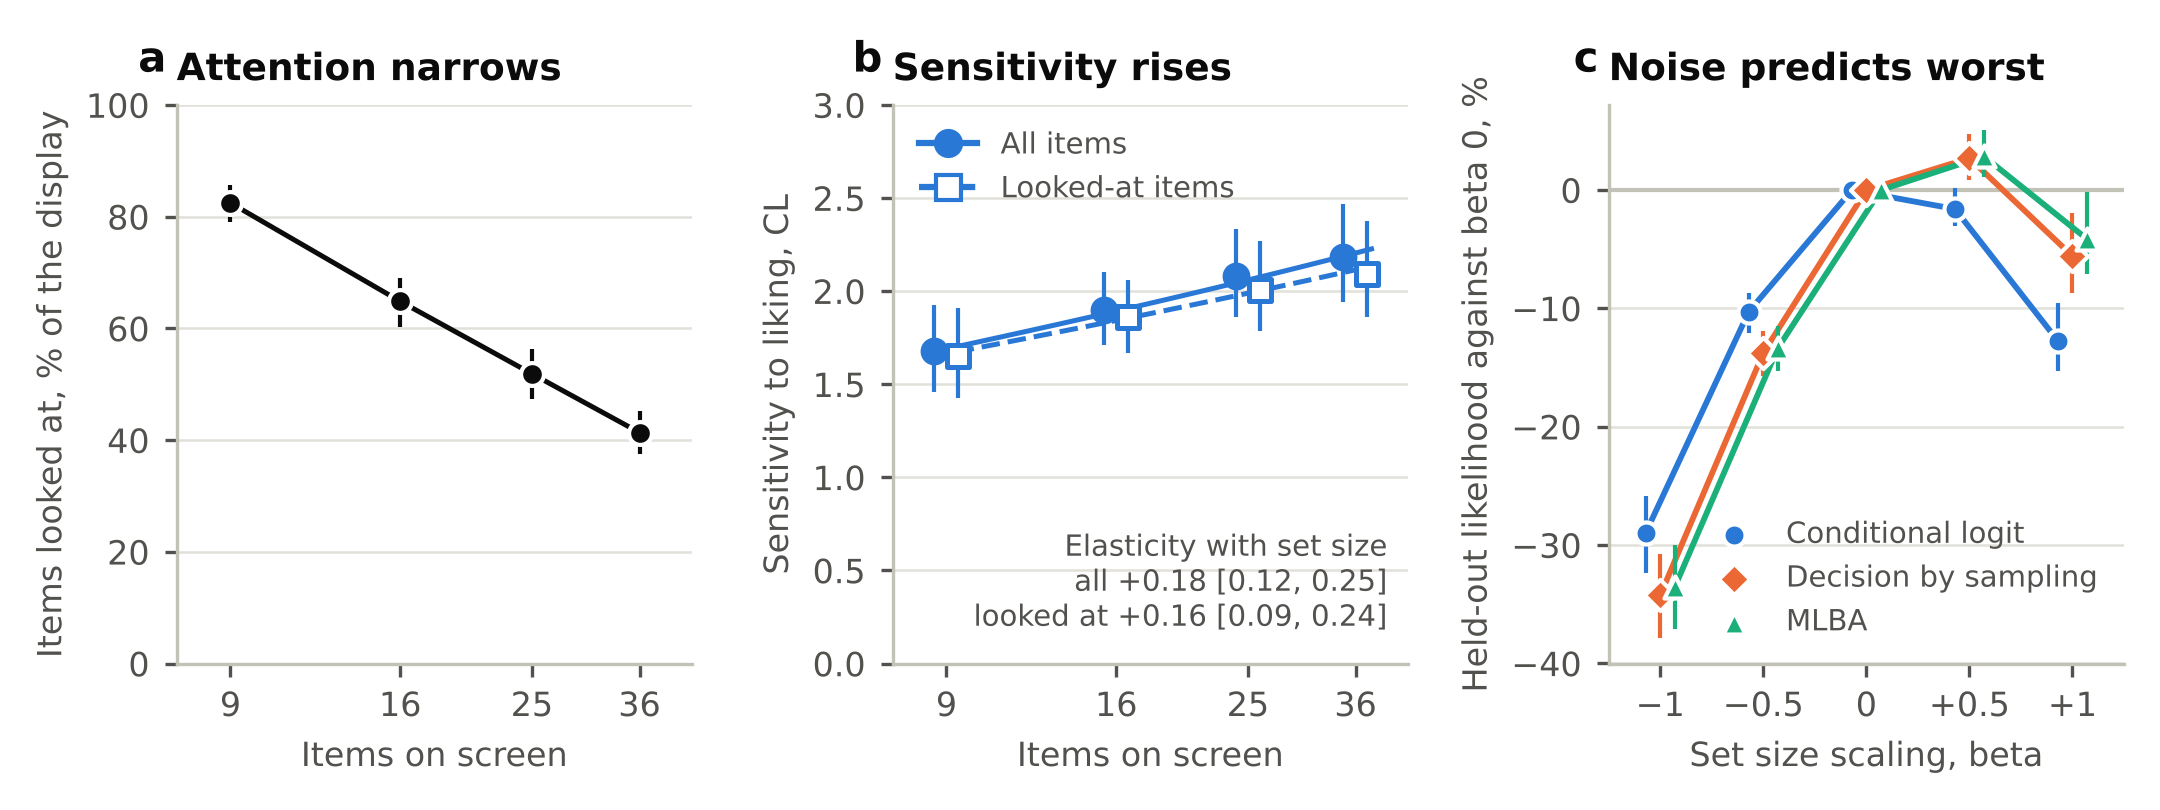

# H1 confirmatory, open snack choice data (Amendment 3)

## C1, choices across screen positions

| Items | Observed | CL held out | Gap |
|---|---|---|---|
| 9 | 99.5 | 99.8 | -0.3 |
| 16 | 99.5 | 99.6 | -0.1 |
| 25 | 99.1 | 99.4 | -0.3 |
| 36 | 98.4 | 99.0 | -0.7 |

- Mean gap -0.3 [-0.8, 0.1] points, slope per doubling -0.2 [-0.7, 0.3] points, supports H1 False.

## C2, set size scaling, held-out likelihood relative to chance

| Model | Version | beta | Times chance | 9 | 16 | 25 | 36 | Minus beta 0 | Minus CL |
|---|---|---|---|---|---|---|---|---|---|
| CL | all | -1.0 | 2.73 | 1.38 | 3.62 | 3.65 | 3.05 | -28.9% [-32.4, -25.8] * |  |
| CL | all | -0.5 | 3.45 | 2.29 | 3.61 | 4.18 | 4.10 | -10.3% [-12.0, -8.7] * |  |
| CL | all | +0.0 | 3.84 | 2.86 | 3.64 | 4.37 | 4.80 |  |  |
| CL | all | +0.5 | 3.78 | 2.79 | 3.62 | 4.37 | 4.64 | -1.6% [-3.1, 0.2] |  |
| CL | all | +1.0 | 3.35 | 2.29 | 3.45 | 4.32 | 3.70 | -12.8% [-15.3, -9.5] * |  |
| DbS_avg | all | -1.0 | 2.33 | 1.02 | 3.48 | 3.1

In [7]:
from overload.experiments import h1_confirmatory
from overload.figures import figure_h1_confirmatory
snack_dir = REPO / "data" / "snack"
if not (snack_dir / "setsize-36_desc-data.csv").exists():
    subprocess.run(["sh", "scripts/fetch_snack_data.sh", str(snack_dir)], cwd=REPO, check=True)
out = REPO / "results" / "h1_confirmatory"
if RECOMPUTE or not (out / "summary.json").exists():
    h1_confirmatory.run(snack_dir, out, replicates=1000, jobs=JOBS)
conf = json.loads((out / "summary.json").read_text())
figure_h1_confirmatory(conf, out / "fig_h1_confirmatory")
display(Image(str(out / "fig_h1_confirmatory.png"), width=900))
print((out / "table_h1_confirmatory.md").read_text())

In [8]:
cmd = [sys.executable, "verification/compare_h1_confirmatory.py",
       "--independent", "verification/independent_snack/results.json", "--results", "results/h1_confirmatory"]
r = subprocess.run(cmd, cwd=REPO, env=env, capture_output=True, text=True)
print(r.stdout[-1500:] or r.stderr[-1500:])

Independent reimplementation against the package, confirmatory H1 on the snack data

Kind            checked   largest difference
clear                29   0
concentration        14   8.63e-17
decision              6   0
descriptive          24   2.22e-16
difference           24   5.55e-16
elasticity           17   4.15e-08
held-out L          150   1.17e-15
interval            248   1.78e-15
p value              31   0
parameter           132   7.11e-15

Every value agrees within tolerance.



**Findings.**

1. The noise account failed again. Letting CL's sensitivity fall with set size (beta -0.5) lowered the held-out likelihood of the chosen snack by 10.3% [8.7, 12.0], clear and as predicted.
2. Raising sensitivity by the pre-registered step (beta +0.5) changed it by -1.6% [-3.1, 0.2] for CL, which is not clear, so C2 does not support H1 by its rule. The same step helped the comparison models, by 2.7% [0.9, 4.8] for DbS_avg and 2.9% [1.1, 5.0] for MLBA_avg.
3. Choices grew sharper with set size. The elasticity of CL's sensitivity was +0.18 [0.12, 0.25], so sensitivity to liking was about 30 percent higher at 36 items than at 9 (fitted to each set size alone, 1.68 against 2.19). The pre-registered step of +0.5 overshot this rise for CL.
4. Attention narrowed. Participants looked at 82.5% of the display at 9 items and 41.4% at 36, and nearly always chose an item they had looked at.
5. The sharper choices did not come from narrowing what was considered. Among the looked-at items the elasticity was +0.16 [0.09, 0.24], not clearly below the value over all items (difference +0.02 [-0.00, 0.04]).
6. Choices did not concentrate on screen positions beyond the value model (mean gap -0.3 points [-0.8, 0.1]).

**Story.** Larger sets made choices sharper, not noisier. In independent data with random displays, people inspected a shrinking share of the options but chose more selectively among what they inspected, which fits search that stops on a well-liked item. The noise account fails in laptops and in snacks, and sharpening holds in both, as the pre-registered contrast for laptops and as a measured elasticity for snacks, where the coarse contrast overshot a modest rise. The paper reports both.